# 3. Fairness evaluation & mitigation

**Goal:** find out whether the baseline model from notebook 2 works equally well for everyone, and test ways to close the gaps.

The logic is the same as in any spurious-correlation problem: a model can look good on average while systematically failing smaller groups.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score

from src.logistic_regression import LogisticRegressionScratch
from src.features import FeatureBuilder, load_processed, race_group, TARGET
from src.metrics import (group_report, worst_group_accuracy,
                         demographic_parity_difference, equal_opportunity_difference, bootstrap_ci)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIGURES = "../figures"
PARAMS = dict(learning_rate=0.1, epochs=30, batch_size=128, l2=1e-3, random_state=0)  # tuned in notebook 2

train, test = load_processed()
y_train, y_test = train[TARGET].to_numpy(), test[TARGET].to_numpy()
for df in (train, test):
    df["race_group"] = race_group(df["race"])
    df["sex_race"] = df["sex"] + " / " + df["race_group"]

## 3.1 Groups and metrics

**Groups:** `sex` (the main focus: largest gap and enough data in both groups), `race` (White, Black, Asian-Pac-Islander, Other) and the intersection `sex × race`.

**Metrics.** Think of the model as deciding who gets offered a premium product (e.g. a credit card for >$50K earners):

| Metric | Plain-language meaning |
|---|---|
| Accuracy per group | How often the model is right for people in this group |
| **Selection rate** | Share of the group the model says earns >50K (who gets the offer) |
| **True positive rate (TPR)** | Of the people who *really* earn >50K, the share the model recognizes. A low TPR means qualified people are missed |
| False positive rate (FPR) | Of the people who earn <=50K, the share wrongly labelled >50K |
| Demographic parity difference | Gap in selection rate between groups |
| **Equal opportunity difference** | Gap in TPR between groups: are qualified men and qualified women recognized equally often? |

Both gap metrics come from the fair-ML literature. Demographic parity formalizes the legal idea of disparate impact (in US employment law, the "four-fifths rule"); equal opportunity was proposed by Hardt, Price & Srebro (2016).

Overall accuracy is not enough, because a group can be failed systematically while the average still looks fine.

## 3.2 Audit the baseline

In [2]:
fb = FeatureBuilder(include_sensitive=True)
X_train, X_test = fb.fit_transform(train), fb.transform(test)
baseline = LogisticRegressionScratch(**PARAMS).fit(X_train, y_train)
pred = baseline.predict(X_test)

print(f"Overall test accuracy: {accuracy_score(y_test, pred):.3f}\n")
print(group_report(y_test, pred, test["sex"]).round(3))

Overall test accuracy: 0.847

              n  base rate  accuracy  selection rate    TPR    FPR
Male    10860.0      0.300     0.807           0.254  0.602  0.105
Female   5421.0      0.109     0.926           0.068  0.469  0.019


**Accuracy is misleading here.** The model is *more* accurate for women (93%) than for men (81%), which might suggest it favours women. But only 11% of women earn >50K, so predicting "<=50K" for a woman is usually right.

The true positive rate tells the real story: the model recognizes **60% of high-earning men but only 47% of high-earning women**. A qualified woman is less likely to be picked up than an equally qualified man: an **equal opportunity gap of 13 percentage points**. Relative to the true rates, the model also under-selects women more: it flags 6.8% of women while 10.9% really earn >50K (62% of the true rate), against 25.4% vs 30.0% for men (85%).

In [3]:
rep = group_report(y_test, pred, test["sex_race"])
# 95% bootstrap confidence interval for TPR in each group
tpr_fn = lambda yt, yp: yp[yt == 1].mean()
ci = {g: bootstrap_ci(tpr_fn, y_test[m], pred[m], n_boot=500)
      for g in rep.index for m in [(test["sex_race"] == g).to_numpy()]}
rep["TPR 95% CI"] = [f"[{ci[g][0]:.2f}, {ci[g][1]:.2f}]" for g in rep.index]
rep.round(3)

,n,base rate,accuracy,selection rate,TPR,FPR,TPR 95% CI
Male / White,9561.0,0.311,0.803,0.265,0.609,0.110,"[0.59, 0.63]"
Female / White,4385.0,0.117,0.922,0.071,0.469,0.018,"[0.43, 0.51]"
Male / Black,808.0,0.170,0.856,0.135,0.474,0.066,"[0.40, 0.56]"
Female / Black,753.0,0.056,0.956,0.039,0.452,0.014,"[0.31, 0.60]"
Male / Asian-Pac-Islander,309.0,0.346,0.799,0.333,0.692,0.144,"[0.60, 0.77]"
Male / Other,182.0,0.198,0.841,0.071,0.278,0.021,"[0.14, 0.41]"
Female / Asian-Pac-Islander,171.0,0.152,0.901,0.123,0.577,0.041,"[0.38, 0.77]"
Female / Other,112.0,0.071,0.920,0.045,0.250,0.029,"[0.00, 0.60]"


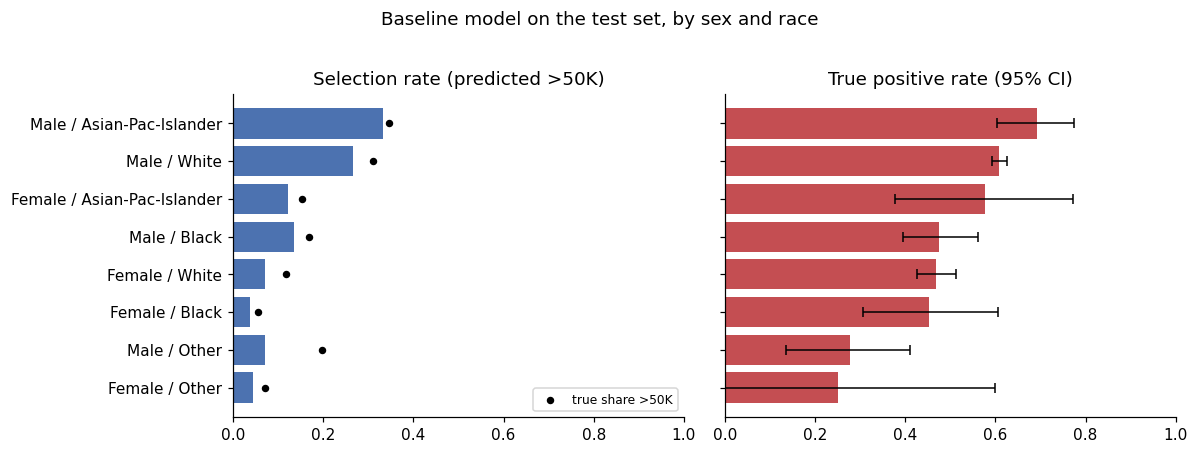

In [4]:
order = rep.sort_values("TPR").index
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, color in [(axes[0], "selection rate", "#4C72B0"), (axes[1], "TPR", "#C44E52")]:
    ax.barh(order, rep.loc[order, col], color=color)
    if col == "selection rate":
        ax.scatter(rep.loc[order, "base rate"], order, color="k", zorder=3, s=15, label="true share >50K")
        ax.legend(loc="lower right", fontsize=8)
    else:
        lo = [ci[g][0] for g in order]; hi = [ci[g][1] for g in order]
        ax.errorbar(rep.loc[order, col], order, xerr=[rep.loc[order, col] - lo, hi - rep.loc[order, col]],
                    fmt="none", ecolor="k", capsize=3, lw=1)
    ax.set_title({"selection rate": "Selection rate (predicted >50K)", "TPR": "True positive rate (95% CI)"}[col])
    ax.set_xlim(0, 1)
plt.suptitle("Baseline model on the test set, by sex and race", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIGURES}/baseline_audit.png", bbox_inches="tight")
plt.show()

Across sex × race, the TPR ranges from 0.69 (Asian-Pacific-Islander men) and 0.61 (white men) down to about 0.47 for Black men and for white women, and lower still for the small "Other" groups.

The confidence intervals show how much to trust each number. For white men the TPR is pinned down to ±0.02. For the smallest groups the interval is very wide (for women in the "Other" group, 0.00 to 0.60), because the test set contains only a handful of high earners in those groups. The intersectional gaps are real for the larger groups, but small-group numbers should not be over-interpreted. That is why the mitigation experiments focus on sex, where both groups are large.

### Can the model see sex even without the `sex` column?
If the remaining features predict sex well, then dropping `sex` does not make the model blind to it.

In [5]:
fb_ns = FeatureBuilder(include_sensitive=False)
Xs_train, Xs_test = fb_ns.fit_transform(train), fb_ns.transform(test)
is_male_train = (train["sex"] == "Male").to_numpy().astype(int)
is_male_test = (test["sex"] == "Male").to_numpy().astype(int)

sex_model = LogisticRegressionScratch(**PARAMS).fit(Xs_train, is_male_train)
print(f"Predicting sex from the non-sensitive features: test ROC AUC = {roc_auc_score(is_male_test, sex_model.predict_proba(Xs_test)):.3f}")
print(f"Accuracy = {accuracy_score(is_male_test, sex_model.predict(Xs_test)):.3f} (majority guess: {is_male_test.mean():.3f})")

Predicting sex from the non-sensitive features: test ROC AUC = 0.929
Accuracy = 0.840 (majority guess: 0.667)


From the other features alone, a model can tell men from women with a **ROC AUC of 0.93**, mostly through `relationship` (Husband/Wife) and `marital-status`, as found in notebook 1. Deleting the `sex` column therefore does not make the model blind to sex.

## 3.3 Mitigation experiments

All models use the same from-scratch logistic regression and the same hyperparameters, and are evaluated on the same test set:

1. **Baseline:** all features, including `sex` and `race`.
2. **Unawareness:** drop `sex` and `race`.
3. **Unawareness + drop proxies:** also drop `relationship` and `marital-status`.
4. **Reweighting (pre-processing):** baseline features, with each person weighted by P(sex) · P(label) / P(sex, label) (Kamiran & Calders, 2012) via `sample_weight` in `fit`. In the weighted data, sex and income are independent, while the overall share of >50K stays the same.
5. **Train-time adjustment:** use `sex` and `race` during training so that the other coefficients are estimated *conditional on* them, then set those columns to their neutral (average) value at prediction time. The sensitive attributes are not used to make predictions.
6. **Group thresholds (post-processing, Hardt, Price & Srebro, 2016):** baseline scores, with a separate decision threshold per sex, chosen on out-of-fold training predictions so that both sexes reach the same TPR. This is a simplified version of the paper's method: the paper chooses the pair of thresholds that minimizes the expected loss subject to equal TPR, while here the target TPR is fixed at the baseline's overall TPR and each sex gets the threshold that reaches it. This **does** use sex at prediction time, which is not legal in every application (e.g. credit decisions in many countries).

In [6]:
def fit_predict_proba(X_tr, y_tr, X_te, sample_weight=None):
    return LogisticRegressionScratch(**PARAMS).fit(X_tr, y_tr, sample_weight=sample_weight).predict_proba(X_te)

scores, thresholds = {}, {}

# 1. Baseline
scores["1. Baseline"] = baseline.predict_proba(X_test)

# 2. Unawareness
scores["2. Unawareness"] = fit_predict_proba(Xs_train, y_train, Xs_test)

# 3. Unawareness + drop proxies
fb_np = FeatureBuilder(include_sensitive=False, exclude=("relationship", "marital-status"))
Xp_train, Xp_test = fb_np.fit_transform(train), fb_np.transform(test)
scores["3. Unawareness + drop proxies"] = fit_predict_proba(Xp_train, y_train, Xp_test)

# 4. Reweighting (Kamiran & Calders): weight = P(sex) * P(label) / P(sex, label)
p_sex = train["sex"].map(train["sex"].value_counts(normalize=True))
p_label = train[TARGET].map(train[TARGET].value_counts(normalize=True))
cell = train["sex"] + "_" + train[TARGET].astype(str)
weights = (p_sex * p_label / cell.map(cell.value_counts(normalize=True))).to_numpy()
print("Weight per (sex, label) cell:", dict(zip(cell, weights.round(2))))
scores["4. Reweighting"] = fit_predict_proba(X_train, y_train, X_test, sample_weight=weights)

# 5. Train-time adjustment: neutralize the sensitive columns at prediction time
X_test_neutral = X_test.copy()
X_test_neutral[:, fb.sensitive_columns()] = 0.0  # 0 = training mean after standardization
scores["5. Train-time adjustment"] = baseline.predict_proba(X_test_neutral)

Weight per (sex, label) cell: {'Male_0': np.float64(1.09), 'Female_0': np.float64(0.85), 'Male_1': np.float64(0.79), 'Female_1': np.float64(2.2)}


In [7]:
# 6. Group thresholds, chosen on out-of-fold predictions of the training set (the test set is never used for tuning)
oof = np.zeros(len(y_train))
for tr, va in StratifiedKFold(5, shuffle=True, random_state=0).split(X_train, y_train):
    oof[va] = fit_predict_proba(X_train[tr], y_train[tr], X_train[va])

target_tpr = (oof[y_train == 1] >= 0.5).mean()  # overall TPR of the baseline at the default threshold
for g in ["Female", "Male"]:
    pos = oof[(train["sex"] == g).to_numpy() & (y_train == 1)]
    thresholds[g] = np.quantile(pos, 1 - target_tpr)  # lowest threshold that still gives the target TPR
print(f"Target TPR: {target_tpr:.3f}   thresholds: " + ", ".join(f"{g} {th:.3f}" for g, th in thresholds.items()))

scores["6. Group thresholds"] = scores["1. Baseline"]
group_threshold = test["sex"].map(thresholds).to_numpy()

Target TPR: 0.596   thresholds: Female 0.340, Male 0.520


In [8]:
def predict_labels(name, proba):
    return (proba >= (group_threshold if name.startswith("6.") else 0.5)).astype(int)

def evaluate(name, proba):
    pred = predict_labels(name, proba)
    rep_sex = group_report(y_test, pred, test["sex"])
    return {
        "accuracy": accuracy_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, proba) if not name.startswith("6.") else np.nan,
        "TPR women": rep_sex.loc["Female", "TPR"],
        "TPR men": rep_sex.loc["Male", "TPR"],
        "EO gap (sex)": equal_opportunity_difference(y_test, pred, test["sex"]),
        "DP gap (sex)": demographic_parity_difference(pred, test["sex"]),
        "EO gap (sex × race)": equal_opportunity_difference(y_test, pred, test["sex_race"]),
        "worst-group acc (sex × race)": worst_group_accuracy(y_test, pred, test["sex_race"]),
    }

comparison = pd.DataFrame({name: evaluate(name, p) for name, p in scores.items()}).T
comparison.round(3)

,accuracy,ROC AUC,TPR women,TPR men,EO gap (sex),DP gap (sex),EO gap (sex × race),worst-group acc (sex × race)
1. Baseline,0.847,0.898,0.469,0.602,0.133,0.187,0.442,0.799
2. Unawareness,0.845,0.899,0.505,0.589,0.084,0.174,0.330,0.790
3. Unawareness + drop proxies,0.815,0.837,0.356,0.425,0.069,0.092,0.356,0.773
4. Reweighting,0.841,0.891,0.637,0.530,0.107,0.092,0.404,0.800
5. Train-time adjustment,0.843,0.896,0.573,0.535,0.038,0.118,0.339,0.800
6. Group thresholds,0.843,NaN,0.590,0.583,0.007,0.138,0.414,0.793


**What each approach does (test set):**

| Approach | Accuracy | EO gap (sex) | Verdict |
|---|---|---|---|
| 1. Baseline | 0.847 | 0.133 | Accurate but unequal: qualified women are missed more often |
| 2. Unawareness | 0.845 | 0.084 | Gap shrinks but stays, because proxies still carry sex |
| 3. + drop proxies | 0.815 | 0.069 | Removes the strongest predictors: worse for *everyone* (TPR drops for both sexes), still not fair |
| 4. Reweighting | 0.841 | 0.107 | Halves the selection-rate gap, but over-corrects TPR: now women 0.64 vs men 0.53 (see below) |
| 5. **Train-time adjustment** | **0.843** | **0.038** | Gap down 70% for −0.4 pt accuracy, without using sex at prediction time |
| 6. **Group thresholds** | **0.843** | **0.007** | Gap closed for −0.4 pt accuracy, but needs sex at decision time |

Notes:
- **Reweighting** gives high-earning women a weight of 2.2 against 0.79 for high-earning men. It removes the link between sex and income in the training data, which is what *demographic parity* asks for: the selection-rate gap halves (0.187 → 0.092) for only 0.6 points of accuracy. It does not target equal opportunity, and it overshoots: the TPR gap reverses direction (women 0.64, men 0.53), and the change in the gap is not distinguishable from noise (see the bootstrap below).
- **Train-time adjustment** sets the sex and race columns to their training mean (0 after standardization). The exact neutral value matters less than it seems: in logistic regression these columns add one term to the log-odds, so giving everyone the same value adds the same constant to every score. The ranking of people, and therefore the ROC AUC, is identical whatever constant is used; the choice only shifts all scores together, which is equivalent to moving the single 0.5 threshold.
- **Group thresholds** use 0.34 for women and 0.52 for men. They were chosen on out-of-fold training predictions, so the test set was never used for tuning.
- **No method fixes the sex × race gap** (0.33–0.44 everywhere). All methods target sex; the remaining gap comes mostly from the small race groups, which would need race-aware methods and, above all, more data.

### Are the differences real? Paired bootstrap
The test set is one sample of 16,281 people, so every number above has sampling noise. To check whether a method really changes accuracy and the gap, I resample test rows with replacement and recompute the difference *method − baseline* on the **same** resampled rows each time. Most people get the same prediction from both models, so their row-to-row variation cancels out, and the interval for the difference is much narrower than two separate intervals would suggest. Nothing is retrained and the official train/test split is untouched.

A difference is clearly real when its 95% interval excludes 0.

In [9]:
sex = test["sex"].to_numpy()
pred_base = predict_labels("1. Baseline", scores["1. Baseline"])
acc_diff = lambda yt, pb, pm: (pm == yt).mean() - (pb == yt).mean()
eo_diff = lambda yt, pb, pm, g: equal_opportunity_difference(yt, pm, g) - equal_opportunity_difference(yt, pb, g)

rows = {}
for name, proba in list(scores.items())[1:]:
    pred_m = predict_labels(name, proba)
    acc_lo, acc_hi = bootstrap_ci(acc_diff, y_test, pred_base, pred_m, n_boot=1000)
    eo_lo, eo_hi = bootstrap_ci(eo_diff, y_test, pred_base, pred_m, sex, n_boot=1000)
    rows[name] = {"Δ accuracy (pts)": round(100 * acc_diff(y_test, pred_base, pred_m), 2),
                  "Δ accuracy 95% CI": f"[{100 * acc_lo:+.2f}, {100 * acc_hi:+.2f}]",
                  "Δ EO gap (pts)": round(100 * eo_diff(y_test, pred_base, pred_m, sex), 1),
                  "Δ EO gap 95% CI": f"[{100 * eo_lo:+.1f}, {100 * eo_hi:+.1f}]"}
pd.DataFrame(rows).T

,Δ accuracy (pts),Δ accuracy 95% CI,Δ EO gap (pts),Δ EO gap 95% CI
2. Unawareness,-0.15,"[-0.29, -0.01]",-4.9,"[-6.6, -3.4]"
3. Unawareness + drop proxies,-3.14,"[-3.67, -2.59]",-6.4,"[-12.2, -1.0]"
4. Reweighting,-0.6,"[-0.93, -0.26]",-2.6,"[-10.6, +6.1]"
5. Train-time adjustment,-0.36,"[-0.64, -0.05]",-9.5,"[-16.9, -0.7]"
6. Group thresholds,-0.32,"[-0.56, -0.10]",-12.6,"[-15.5, -3.8]"


- **The accuracy costs are real but small.** Every interval lies entirely below 0, so no method is free, but for train-time adjustment and group thresholds the cost is at most about 0.6 points. Dropping the proxies costs 3 points, clearly more than anything else.
- **The gap reductions of methods 2, 3, 5 and 6 are real**: their intervals lie entirely below 0. The intervals are wide (several points) because the test set has only about 590 high-earning women.
- **Reweighting's change in the EO gap is not distinguishable from noise** (the interval includes 0), which matches the point above: it improves demographic parity, not equal opportunity.

## 3.4 Trade-offs

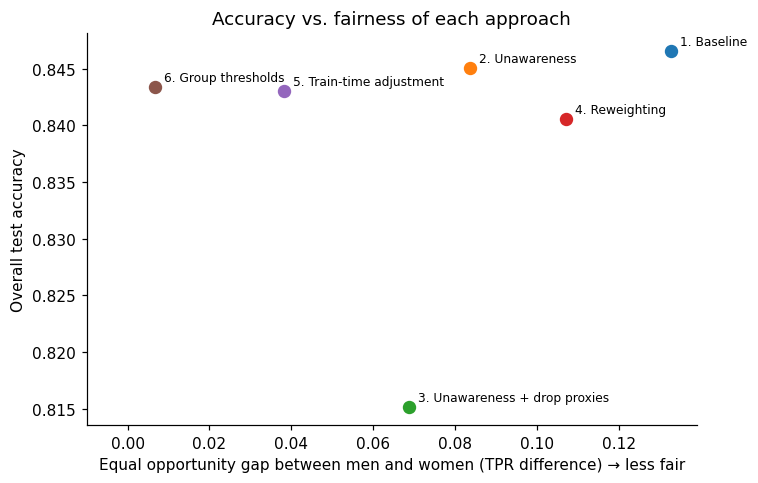

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, row in comparison.iterrows():
    ax.scatter(row["EO gap (sex)"], row["accuracy"], s=60)
    ax.annotate(name, (row["EO gap (sex)"], row["accuracy"]), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Equal opportunity gap between men and women (TPR difference) → less fair")
ax.set_ylabel("Overall test accuracy")
ax.set_title("Accuracy vs. fairness of each approach")
ax.set_xlim(left=-0.01)
plt.tight_layout()
plt.savefig(f"{FIGURES}/tradeoff.png", bbox_inches="tight")
plt.show()

**There is no free lunch, but there is a cheap one.** The naive fixes (dropping columns) lose more accuracy than they gain in fairness. The targeted fixes (5 and 6) remove most or all of the equal-opportunity gap for less than half a percentage point of accuracy, and the paired bootstrap confirms both the cost and the improvement are real.

**Recommendation:**
- If the law and the use case allow sex to be used at decision time and equal opportunity is the goal → **group thresholds** (6).
- If sex may not be used to make decisions, which is common in credit and hiring → **train-time adjustment** (5). It uses sex only to estimate the other effects correctly, then predicts without it.
- If the goal is instead equal selection rates (demographic parity) → **reweighting** (4), which halves that gap at a small accuracy cost.
- Either way, report per-group TPR and selection rate alongside accuracy, and monitor them after deployment.

## Conclusion

- **Overall accuracy hides unfairness.** The baseline is 85% accurate and even *more* accurate for women, yet it recognizes only 47% of high-earning women vs 60% of high-earning men.
- **"Just remove the sensitive column" does not work.** The remaining features predict sex with an AUC of 0.93; unawareness only shrinks the gap from 13 to 8 points, and removing the proxies as well hurts everyone.
- **Targeted methods work well.** Adjusting for sex during training cuts the gap to 4 points, and group-specific thresholds close it entirely, each for about 0.4 points of accuracy (paired bootstrap: the cost is real but below 0.7 points).
- **The choice of fairness metric is a business and legal decision, not a technical one.** Reweighting halves the demographic parity gap but over-corrects equal opportunity, while group thresholds do the reverse. When base rates differ (30% vs 11%), the two metrics cannot both be satisfied.

### Limitations
- The data are from the 1994 US Current Population Survey (CPS), and the $50K threshold is not adjusted for inflation. Ding et al. (2021), *Retiring Adult*, explain why newer data are better for fairness research.
- One train/test split: the paired bootstrap covers sampling noise in the test set but not the randomness of training, and the numbers for the small race groups have wide confidence intervals.
- The sex variable in the census is binary, so non-binary people are not represented.
- Fair predictions do not undo the inequality in the underlying data. The model reflects the 1994 labour market, including its gaps.

### References
- Hardt, M., Price, E., & Srebro, N. (2016). Equality of opportunity in supervised learning. *NeurIPS*. https://arxiv.org/abs/1610.02413
- Kamiran, F., & Calders, T. (2012). Data preprocessing techniques for classification without discrimination. *Knowledge and Information Systems*, 33(1), 1–33.
- Kleinberg, J., Mullainathan, S., & Raghavan, M. (2017). Inherent trade-offs in the fair determination of risk scores. *ITCS*. https://arxiv.org/abs/1609.05807
- Ding, F., Hardt, M., Miller, J., & Schmidt, L. (2021). Retiring Adult: New datasets for fair machine learning. *NeurIPS*. https://arxiv.org/abs/2108.04884